# Siapa Member Bernilai Tinggi? RFM dan CLV 52 Minggu

RFM menjawab pertanyaan deskriptif: siapa yang belanja paling banyak, paling sering, paling baru. CLV mencoba pertanyaan yang lebih sulit — berapa nilai ke depan tiap member — dengan BG/NBD memodelkan kapan mereka berhenti belanja dan Gamma-Gamma memodelkan berapa nilai tiap kunjungan.

Lalu pertanyaan ketiga, yang paling penting: apakah model itu benar-benar menambah informasi di atas cara paling sederhana — merata-ratakan historis tiap member? **Jawabannya: tidak.** Pada 26 minggu terakhir yang disisihkan sebagai holdout, model kalah dari baseline naif di semua metrik (MAE 322,2 vs 307,6; 95% CI selisih +8,6 s.d. +20,5). Belanja grocery yang hampir periodik membuat rata-rata historis sangat sulit dikalahkan — dan justru itu temuan yang layak ditunjukkan.

Semua nilai dalam USD nominal; horizon selalu dinyatakan eksplisit (CLV **52 minggu**, bukan "lifetime").

## 0. Setup

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.clv import (
    CALIBRATION_END_WEEK,
    CLV_HORIZON_WEEKS,
    HOLDOUT_WEEKS,
    build_summary,
    evaluate_holdout,
    fit_bg_nbd,
    fit_gamma_gamma,
    frequency_monetary_correlation,
    predict_spending,
)
from src.features import PROCESSED_DIR, build_rfm, save_parquet

panel = pd.read_parquet(PROCESSED_DIR / "hh_week.parquet")
assert len(panel) == 255_000 and panel["household_key"].nunique() == 2_500
print(f"panel hh_week: {len(panel):,} baris | pandas {pd.__version__}")

panel hh_week: 255,000 baris | pandas 3.0.3


## 1. RFM: baseline deskriptif yang sulit dikalahkan

Kuintil R/F/M dihitung dari seluruh 102 minggu, seimbang ukurannya (500 household per kuintil), arahnya diseragamkan — kuintil 5 selalu berarti lebih bernilai. Untuk keperluan validasi model tersedia juga versi window kalibrasi (minggu 1–76); tabel distribusi di bawah memakai periode penuh.

In [2]:
rfm_full = build_rfm(panel, 102)
rfm_cal = build_rfm(panel, CALIBRATION_END_WEEK)
print(f"populasi full: {len(rfm_full):,} | populasi kalibrasi (aktif <= minggu {CALIBRATION_END_WEEK}): {len(rfm_cal):,} "
      f"({2_500 - len(rfm_cal)} household mulai belanja setelah minggu {CALIBRATION_END_WEEK} — dikecualikan dari validasi, dilaporkan)")

dist = rfm_full.groupby("f_quintile").agg(
    n=("household_key", "size"),
    mean_frequency=("frequency", "mean"),
    mean_recency=("recency", "mean"),
    mean_monetary=("monetary", "mean"),
    total_net_spend=("total_net_spend", "sum"),
)
dist["spend_share"] = dist["total_net_spend"] / dist["total_net_spend"].sum()
dist.round(2)

populasi full: 2,500 | populasi kalibrasi (aktif <= minggu 76): 2,498 (2 household mulai belanja setelah minggu 76 — dikecualikan dari validasi, dilaporkan)


,n,mean_frequency,mean_recency,mean_monetary,total_net_spend,spend_share
f_quintile,,,,,,
1,500,14.34,10.64,32.28,232518.94,0.04
2,500,31.97,3.21,35.53,567654.18,0.09
3,500,49.70,2.01,41.22,1028700.66,0.16
4,500,66.98,1.00,50.14,1684026.25,0.25
5,500,84.97,0.23,72.25,3096040.86,0.47


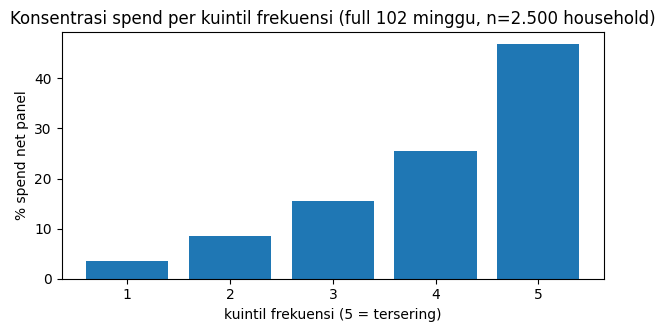

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(dist.index, dist["spend_share"] * 100, color="#1f77b4")
ax.set(
    title="Konsentrasi spend per kuintil frekuensi (full 102 minggu, n=2.500 household)",
    xlabel="kuintil frekuensi (5 = tersering)",
    ylabel="% spend net panel",
)
plt.show()

## 2. Menyiapkan data model: minggu aktif sebagai "transaksi"

Pada grain mingguan, satu "transaksi" = satu minggu berbelanja, berapa pun jumlah basket-nya — menyederhanakan belanja multi-basket dan konsisten dengan panel. Konvensi input model: `frequency` = minggu aktif setelah minggu pertama, `recency` = jarak minggu aktif terakhir ke minggu aktif pertama, `T` = lama pajanan, `monetary` = rata-rata net per minggu aktif. Validasi memakai window kalibrasi minggu 1–76; prediksi yang dipublikasikan memakai seluruh 102 minggu.

,frequency,recency,T,monetary
0.1,9.0,55.0,60.0,14.83
0.5,35.0,64.0,65.0,37.61
0.9,60.0,72.0,73.0,84.26


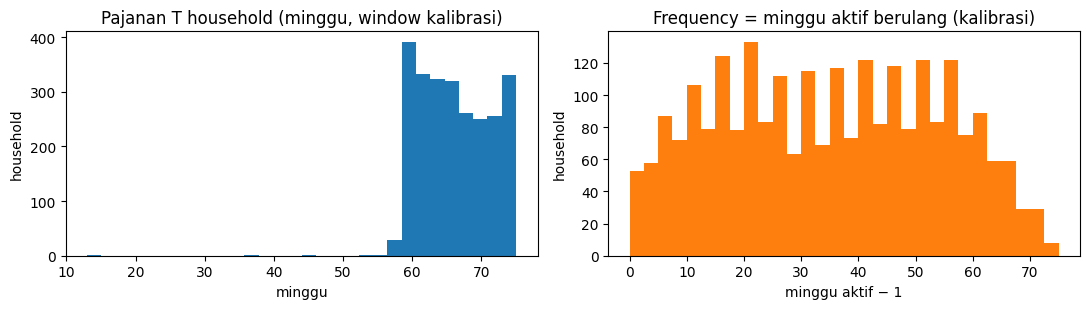

In [4]:
s_cal = build_summary(panel, CALIBRATION_END_WEEK)
s_full = build_summary(panel, 102)
q = s_cal[["frequency", "recency", "T", "monetary"]].quantile([0.1, 0.5, 0.9]).round(2)
display(q)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(s_cal["T"], bins=30, color="#1f77b4")
axes[0].set(title="Pajanan T household (minggu, window kalibrasi)", xlabel="minggu", ylabel="household")
axes[1].hist(s_cal["frequency"], bins=30, color="#ff7f0e")
axes[1].set(title="Frequency = minggu aktif berulang (kalibrasi)", xlabel="minggu aktif − 1", ylabel="household")
plt.tight_layout()
plt.show()

## 3. BG/NBD: memodelkan "masih hidup atau sudah pergi"

BG/NBD memisahkan dua proses: seberapa sering member belanja, dan seberapa mungkin mereka sudah berhenti. Dua fit dilakukan — kalibrasi (untuk diuji) dan periode penuh (untuk dipublikasikan); fit periode penuh membutuhkan penalizer kecil untuk konvergen, praktik standar saat permukaan likelihood mendatar.

In [5]:
bgf_cal = fit_bg_nbd(s_cal)
bgf_full = fit_bg_nbd(s_full)
params = pd.DataFrame(
    {"kalibrasi (1-76)": bgf_cal.params_, "full (1-102)": bgf_full.params_}
).round(4)
params.loc["penalizer_coef"] = [bgf_cal.penalizer_coef, bgf_full.penalizer_coef]
params

D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\tracer.py:93: RuntimeWarning: divide by zero encountered in log
  return f_raw(*args, **kwargs)
D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\numpy\numpy_vjps.py:166: RuntimeWarning: divide by zero encountered in divide
  defvjp(anp.log, lambda ans, x: lambda g: g / x)
D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\numpy\numpy_vjps.py:81: RuntimeWarning: invalid value encountered in multiply
  lambda ans, x, y: unbroadcast_f(x, lambda g: y * g),
D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\numpy\numpy_vjps.py:163: RuntimeWarning: invalid value encountered in multiply
  defvjp(anp.exp, lambda ans, x: lambda g: ans * g)


  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: -150.29603985572498
        x: [ 1.062e+00 -2.923e+00  8.058e+00  1.564e+01]
      nit: 55
      jac: [ 2.243e-06 -4.827e-06  2.351e-09 -1.102e-08]
 hess_inv: [[ 1.715e+00  1.578e+00  1.850e+01  1.734e+01]
            [ 1.578e+00  1.751e+00  2.418e+01  2.292e+01]
            [ 1.850e+01  2.418e+01  1.304e+07  1.304e+07]
            [ 1.734e+01  2.292e+01  1.304e+07  1.304e+07]]
     nfev: 114
     njev: 103


D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\tracer.py:93: RuntimeWarning: divide by zero encountered in log
  return f_raw(*args, **kwargs)
D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\numpy\numpy_vjps.py:166: RuntimeWarning: divide by zero encountered in divide
  defvjp(anp.log, lambda ans, x: lambda g: g / x)
D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\numpy\numpy_vjps.py:81: RuntimeWarning: invalid value encountered in multiply
  lambda ans, x, y: unbroadcast_f(x, lambda g: y * g),
D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\autograd\numpy\numpy_vjps.py:163: RuntimeWarning: invalid value encountered in multiply
  defvjp(anp.exp, lambda ans, x: lambda g: ans * g)


,kalibrasi (1-76),full (1-102)
r,2.7930,2.2759
alpha,5.2312,4.2766
a,0.0200,0.0032
b,10.3100,0.5059
penalizer_coef,0.0000,0.0100


pred minggu aktif 26w: p50=13.7 | p99=25.0 (<= 26 OK) | p_alive: p10=0.99 p50=1.00 p90=1.00


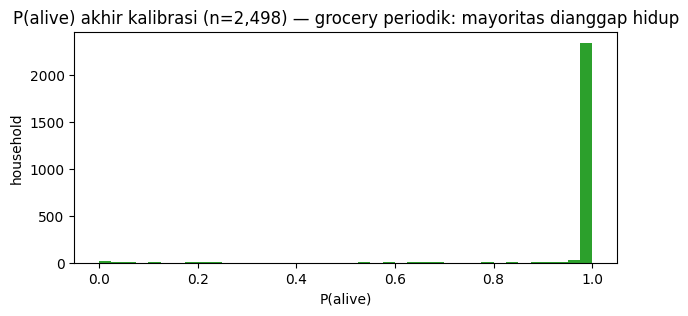

In [6]:
ggf_cal = fit_gamma_gamma(s_cal)
pred26 = predict_spending(bgf_cal, ggf_cal, s_cal, HOLDOUT_WEEKS)
print(
    f"pred minggu aktif 26w: p50={pred26['predicted_purchases'].quantile(.5):.1f} | "
    f"p99={pred26['predicted_purchases'].quantile(.99):.1f} (<= 26 OK) | "
    f"p_alive: p10={pred26['p_alive'].quantile(.1):.2f} p50={pred26['p_alive'].quantile(.5):.2f} p90={pred26['p_alive'].quantile(.9):.2f}"
)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(pred26["p_alive"], bins=40, color="#2ca02c")
ax.set(
    title=f"P(alive) akhir kalibrasi (n={len(pred26):,}) — grocery periodik: mayoritas dianggap hidup",
    xlabel="P(alive)",
    ylabel="household",
)
plt.show()

## 4. Gamma-Gamma — dan asumsi yang langsung dipatahkan data

Gamma-Gamma mengestimasi nilai per kunjungan dengan satu asumsi kunci: frekuensi tidak berkorelasi dengan monetary. Data ini berkata sebaliknya — household yang sering belanja juga belanja lebih besar per minggunya (Spearman ρ ≈ 0,43). Asumsi dilanggar material; `clv_52w` mewarisi bias ini dan labelnya menyertainya.

Spearman frequency-monetary (kalibrasi): rho=0.429, p=1.80e-112
Gamma-Gamma (full): {'p': 0.18, 'q': 4.446, 'v': 947.416} | penalizer: 0.0


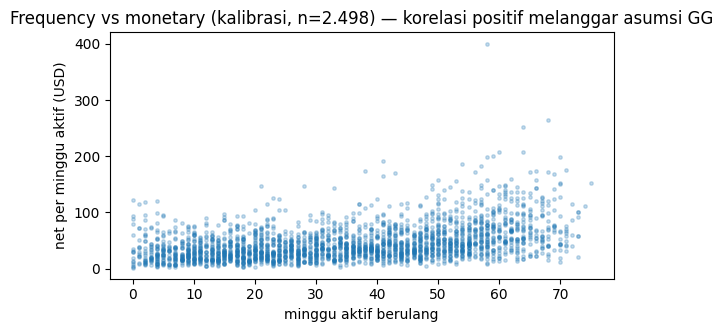

In [7]:
corr = frequency_monetary_correlation(s_cal)
print(f"Spearman frequency-monetary (kalibrasi): rho={corr['spearman_rho']:.3f}, p={corr['p_value']:.2e}")
ggf_full = fit_gamma_gamma(s_full)
print("Gamma-Gamma (full):", {k: round(v, 3) for k, v in ggf_full.params_.items()},
      "| penalizer:", ggf_full.penalizer_coef)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.scatter(s_cal["frequency"], s_cal["monetary"], s=6, alpha=0.25, color="#1f77b4")
ax.set(
    title="Frequency vs monetary (kalibrasi, n=2.498) — korelasi positif melanggar asumsi GG",
    xlabel="minggu aktif berulang",
    ylabel="net per minggu aktif (USD)",
)
plt.show()

## 5. CLV 52 minggu: prediksi yang dipublikasikan

Prediksi final dari fit periode penuh: jumlah minggu aktif yang diharapkan × nilai bersih per minggu aktif, horizon 52 minggu. Tiga household yang hanya terlihat satu minggu sepanjang data ditangani rumus closed-form khusus (implementasi library mengembalikan NaN untuk kasus ini).

CLV 52 minggu (USD, net, n=2,500): p10=314 | p50=1,050 | p90=3,133 | p99=6,363


D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


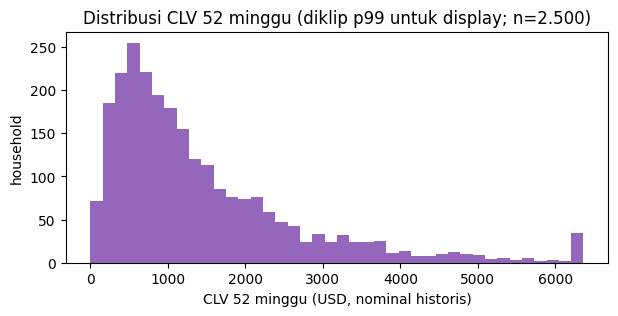

In [8]:
clv = (
    predict_spending(bgf_full, ggf_full, s_full, CLV_HORIZON_WEEKS)
    .rename(
        columns={
            "predicted_purchases": "predicted_purchases_52w",
            "predicted_spend": "clv_52w",
        }
    )
)
hh_clv = rfm_full.merge(
    clv[["household_key", "p_alive", "predicted_purchases_52w", "clv_52w"]],
    on="household_key",
    validate="1:1",
)
save_parquet(hh_clv, PROCESSED_DIR / "hh_clv.parquet")
print(
    f"CLV 52 minggu (USD, net, n={len(hh_clv):,}): "
    + " | ".join(f"p{int(p*100)}={hh_clv['clv_52w'].quantile(p):,.0f}" for p in (0.1, 0.5, 0.9, 0.99))
)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(hh_clv["clv_52w"].clip(upper=hh_clv["clv_52w"].quantile(0.99)), bins=40, color="#9467bd")
ax.set(
    title="Distribusi CLV 52 minggu (diklip p99 untuk display; n=2.500)",
    xlabel="CLV 52 minggu (USD, nominal historis)",
    ylabel="household",
)
plt.show()

## 6. Ujian sebenarnya: model vs rata-rata historis

Baseline naifnya sengaja dibuat kuat: rata-rata spend mingguan tiap household sendiri, diekstrapolasi ke horizon. Kalau model tidak mengalahkan ini, ia tidak menambah apa-apa. Evaluasi pada holdout 26 minggu, dengan bootstrap 1.000 resample untuk CI selisih MAE.

,metrik (holdout 26 minggu),nilai
0,n_households,"2,498"
1,horizon_weeks,26
2,mae_model,322.19
3,rmse_model,488.45
4,mae_naive,307.64
5,rmse_naive,476.31
6,spearman_model_actual,0.77
7,spearman_naive_actual,0.78
8,mae_diff_p2.5,8.59
9,mae_diff_p97.5,20.50


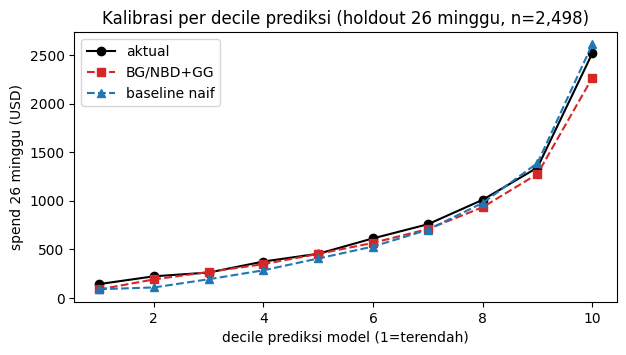

In [9]:
metrics, per_hh = evaluate_holdout(panel, bgf_cal, ggf_cal, s_cal)
metrics_df = pd.DataFrame(
    [(k, f"{v:,.2f}" if isinstance(v, float) else f"{v:,}") for k, v in metrics.items()],
    columns=["metrik (holdout 26 minggu)", "nilai"],
)
display(metrics_df)

per_hh = per_hh.assign(
    decile=pd.qcut(per_hh["predicted_spend"].rank(method="first"), 10, labels=False) + 1
)
cal_tbl = (
    per_hh.groupby("decile")
    .agg(actual=("actual_spend", "mean"), model=("predicted_spend", "mean"), naive=("naive_predicted_spend", "mean"))
)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cal_tbl.index, cal_tbl["actual"], "o-", label="aktual", color="black")
ax.plot(cal_tbl.index, cal_tbl["model"], "s--", label="BG/NBD+GG", color="#d62728")
ax.plot(cal_tbl.index, cal_tbl["naive"], "^--", label="baseline naif", color="#1f77b4")
ax.set(
    title=f"Kalibrasi per decile prediksi (holdout 26 minggu, n={metrics['n_households']:,})",
    xlabel="decile prediksi model (1=terendah)",
    ylabel="spend 26 minggu (USD)",
)
ax.legend()
plt.show()

## Kesimpulan: kalah, dan itu penting diketahui

- Model kalah di semua metrik: MAE 322,2 vs 307,6; RMSE 488,5 vs 476,3; korelasi Spearman prediksi–aktual 0,773 vs 0,780. Selisih MAE +14,6 (95% CI +8,6 s.d. +20,5) — kalahnya konsisten, bukan noise.
- Interpretasi: belanja grocery hampir periodik. Rata-rata historis tiap member sudah menangkap hampir semua sinyal; struktur "dropout" BG/NBD (yang nyaris nol di data ini) tidak menambah informasi.
- Konsekuensi praktis: `clv_52w` dipakai hanya sebagai deskriptor berlabel asumsi; RFM kuintil dan baseline historis tetap acuan untuk keputusan targeting. Membangun presisi di atas BG/NBD di data seperti ini akan menyesatkan.
- Gamma-Gamma menambah catatan sendiri: asumsi independensi frekuensi–monetary dilanggar (ρ ≈ 0,43), jadi `clv_52w` bukan angka presisi — dan tidak dipresentasikan seolah-olah begitu.

## Batasan

- Kualitas prediksi diukur pada horizon 26 minggu; kualitas untuk 52 minggu adalah ekstrapolasi dari bukti itu — asumsi yang dinyatakan, bukan terukur.
- 2 household mulai belanja setelah minggu 76 dikecualikan dari validasi; 3 household sekali-belanja ditangani closed-form.
- Fit periode penuh memakai penalizer 0,01; tanpa itu tidak konvergen.
- Semua nominal USD historis; tidak ada klaim kausal di notebook ini.